<div style="background: linear-gradient(120deg, #102b43 0%, #174d5b 58%, #1c716d 100%); color: #ffffff; border-radius: 20px; padding: 36px 40px; margin: 4px 0 28px 0;">
  <div style="font: 700 12px/1.4 Arial, sans-serif; letter-spacing: 0.18em; color: #bce9e1;">CHEMINFORMATICS · HANDS-ON NOTEBOOK</div>
  <h1 style="font: 700 42px/1.12 Arial, sans-serif; color: #ffffff; margin: 15px 0 10px 0;">Digital chemical reactions</h1>
  <p style="font: 18px/1.55 Arial, sans-serif; color: #e2f1f0; margin: 0; max-width: 700px;">From molecular structures to reaction rules and candidate products.</p>
</div>

![The learning route from SMILES to digital reactions](data/images/digital_reaction_workflow.svg)

We will begin with familiar structure files and ask how a computer reads a molecule. From there, we will use SMARTS to find chemical features, then turn a structural pattern into a reaction rule. The Mn example shows how the same ideas can support a real research workflow. An optional appendix at the end takes you from a ChemDraw scheme to a reaction that RDKit can test.

Run the notebook from top to bottom with the accompanying `data/` folder beside it. The first code cell loads the Python tools used throughout; it does not produce a figure. Later cells build on the structures and reaction rules created above them.

> **Keep in mind:** a digital reaction proposes structures. Chemical judgment and experimental validation determine whether those proposals are useful.


In [1]:
# These imports give us one toolkit for structures, tables, and reaction rules.

from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem.Draw import IPythonConsole
import pandas as pd
from rdkit.Chem import AllChem
from rdkit.Chem import SDWriter, SDMolSupplier
from rdkit.Chem import rdChemReactions
from pathlib import Path

## 1. Molecules as data

<div style="border-left: 6px solid #2b7d86; background: #f5f8fa; border-radius: 0 14px 14px 0; padding: 15px 20px; margin: 12px 0 22px 0;">
  <div style="font: 700 11px/1.4 Arial, sans-serif; letter-spacing: 0.16em; color: #2b7d86;">START WITH FAMILIAR STRUCTURES</div>
  <div style="font: 16px/1.55 Arial, sans-serif; color: #29485c; margin-top: 5px;">Read structures from common experimental data files and check their visual representation.</div>
</div>


### 1.1. Read SMILES from a CSV

A list of compounds often reaches the lab as a spreadsheet. In our small CSV, each row pairs a name with a SMILES string. The name helps us recognize the compound; the SMILES tells RDKit which atoms and bonds it contains.

We will read the table, turn each SMILES into a molecule, and place the drawings next to their names. This first visual check matters: before searching or transforming a structure, we want to know that the computer has read the compound we intended.


     code_name    SMILES
0      ethanol       CCO
1      benzene  c1ccccc1
2  acetic_acid   CC(=O)O

Number of molecules created: 3

Molecules: [<rdkit.Chem.rdchem.Mol object at 0x000001CA81DE7ED0>, <rdkit.Chem.rdchem.Mol object at 0x000001CA81E9C0B0>, <rdkit.Chem.rdchem.Mol object at 0x000001CA81E9C120>]


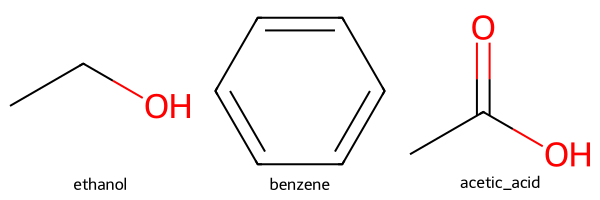

In [2]:
# A molecule list is useful only after we verify that its SMILES become the structures we expect.

df = pd.read_csv("data/molecules.csv")
print(df)

molecules = []

# Parsing turns each text entry into atoms and bonds RDKit can search.
for smi in df["SMILES"]:
    mol = Chem.MolFromSmiles(smi)
    molecules.append(mol)

print(f"\nNumber of molecules created: {len(molecules)}")
print(f"\nMolecules: {molecules}")

# Names under the drawings help catch swapped rows or incorrect structures.
Draw.MolsToGridImage(
    molecules,
    molsPerRow=3,
    subImgSize=(200, 200),
    legends=df["code_name"].tolist()
)


If you have a CSV or SDF from your own work, you can try it here too. A quick look at the drawings is often the best way to catch a structure that was entered or exported incorrectly.

## 2. SMARTS: find the chemistry you care about

<div style="border-left: 6px solid #2b7d86; background: #f5f8fa; border-radius: 0 14px 14px 0; padding: 15px 20px; margin: 12px 0 22px 0;">
  <div style="font: 700 11px/1.4 Arial, sans-serif; letter-spacing: 0.16em; color: #2b7d86;">RECOGNIZE A FUNCTIONAL GROUP</div>
  <div style="font: 16px/1.55 Arial, sans-serif; color: #29485c; margin-top: 5px;">Use a structural pattern to select molecules and highlight the atoms that match.</div>
</div>


### 2.1. What is SMARTS?

Once we trust the structures, we can ask a chemical question of them. Looking through a few drawings is easy; looking through hundreds is not. SMARTS gives us a way to describe a feature such as a nitrogen atom or a carbonyl group and ask RDKit to search for it.

SMILES represents a particular molecule. SMARTS represents a pattern that may occur in many molecules. First we will ask a yes-or-no question; later we will ask which atoms made the answer positive.

### 2.2. Match a functional group

Consider triethylamine. We know from its structure that it contains nitrogen, so it is a useful first test. We will turn the SMILES into a molecule, define a nitrogen SMARTS pattern, and ask RDKit whether the pattern is present. The result is simply True or False: no reaction has taken place, and no new molecule has been made.


In [3]:
# Triethylamine is a known positive case for a nitrogen pattern.

smiles = "CCN(CC)CC"
print("SMILES string:", smiles)

mol = Chem.MolFromSmiles(smiles)

print("Type of mol object:", type(mol))



# This query asks for nitrogen anywhere in the molecule.
smarts_pattern = "N"

print("\nSMARTS pattern:", smarts_pattern)

pattern_mol = Chem.MolFromSmarts(smarts_pattern)

print("Type of SMARTS object:", type(pattern_mol))



# The result is a Boolean that can later drive a filter.
contains_nitrogen = mol.HasSubstructMatch(pattern_mol)

print("\nDoes the molecule contain nitrogen?")
print(contains_nitrogen)
print("Type of result:", type(contains_nitrogen))


SMILES string: CCN(CC)CC
Type of mol object: <class 'rdkit.Chem.rdchem.Mol'>

SMARTS pattern: N
Type of SMARTS object: <class 'rdkit.Chem.rdchem.Mol'>

Does the molecule contain nitrogen?
True
Type of result: <class 'bool'>


The nitrogen query gives the answer we expected. Its real value appears when the same question is asked of a whole collection. We will start with five familiar compounds and display them together, so we can see the full set before deciding which ones contain a carbonyl group.


All molecules (before filtering):


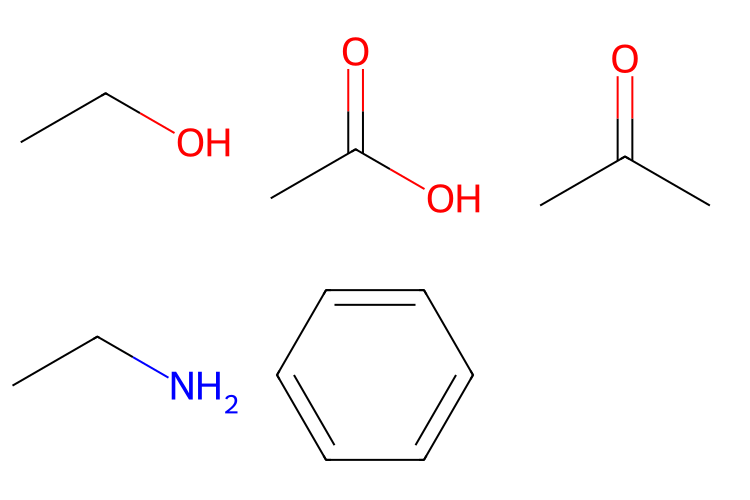

In [4]:
# Start with a small mixed set so the effect of the filter is easy to see.

smiles_list = [
    "CCO",        # ethanol
    "CC(=O)O",    # acetic acid
    "CC(=O)C",    # acetone
    "CCN",        # ethylamine
    "c1ccccc1"    # benzene
]

molecules = [Chem.MolFromSmiles(smi) for smi in smiles_list]

print("All molecules (before filtering):")
display(Draw.MolsToGridImage(
    molecules,
    molsPerRow=3,
    subImgSize=(250, 250)
))

With the five structures in view, we can now ask which of them contain a carbonyl group. The same SMARTS pattern is checked against each molecule; compare the new grid with the complete set above.



Molecules containing a carbonyl group:


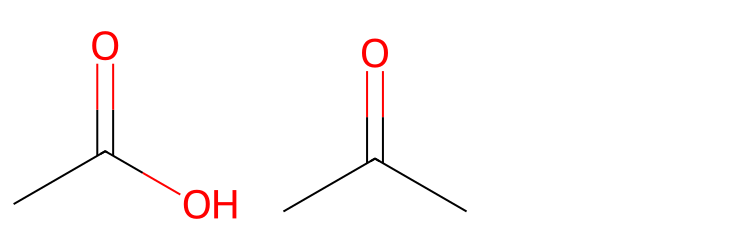

In [5]:
# A carbonyl query keeps only structures with a C=O bond.

smarts = "[C]=[O]"
pattern = Chem.MolFromSmarts(smarts)

filtered_mols = []

# Apply one chemical question consistently to every structure.
for mol in molecules:
    if mol.HasSubstructMatch(pattern):
        filtered_mols.append(mol)

print("\nMolecules containing a carbonyl group:")
display(Draw.MolsToGridImage(
    filtered_mols,
    molsPerRow=3,
    subImgSize=(250, 250)
))

### 2.3. Locate and highlight a match

A yes-or-no answer tells us which molecules to keep, but not where a pattern was found. That distinction matters when a structure has more than one possible site. Acetone is simple enough to inspect by eye, so we will use it to connect RDKit's atom indices to atoms in a drawing.


Molecule: CC(=O)C


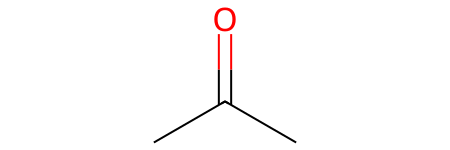

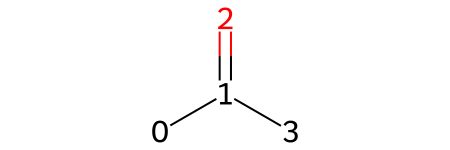

In [6]:
# Atom indices let us connect a text match to a position in the drawing.

smiles = "CC(=O)C"
mol = Chem.MolFromSmiles(smiles)
print("Molecule:", smiles)
display(mol)

# These are RDKit atom indices, not reaction atom-map labels.
for atom in mol.GetAtoms():
    atom.SetProp("atomLabel", str(atom.GetIdx()))
display(mol)


The numbers on acetone are RDKit's atom indices. They are labels for positions in this molecule, not the atom-map numbers used later in reactions. When we search for the carbonyl pattern, RDKit returns the matching indices; highlighting those atoms lets us check that the query has selected the C=O bond we meant.



SMARTS pattern: [C]=[O]
Number of matches: 1
Matches returned: ((1, 2),)


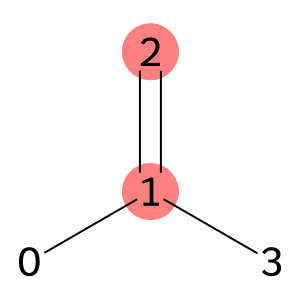

In [7]:
# The carbonyl match returns the indices that we can highlight.

smarts = "[C]=[O]"
pattern = Chem.MolFromSmarts(smarts)

# Keep every match; a larger molecule may contain several sites.
matches = mol.GetSubstructMatches(pattern)

print("\nSMARTS pattern:", smarts)
print("Number of matches:", len(matches))
print("Matches returned:", matches)

highlight_atoms = [idx for match in matches for idx in match]
display(Draw.MolToImage(
    mol,
    highlightAtoms=highlight_atoms,
    size=(300, 300)
))


Acetone gives us one clear match. On a more decorated molecule, different SMARTS patterns can point to very different parts of the structure. The next example asks several questions of the same aromatic compound. Compare the count printed for each pattern with the atoms highlighted in the grid: a query is useful only when its matches mean what we think they mean.


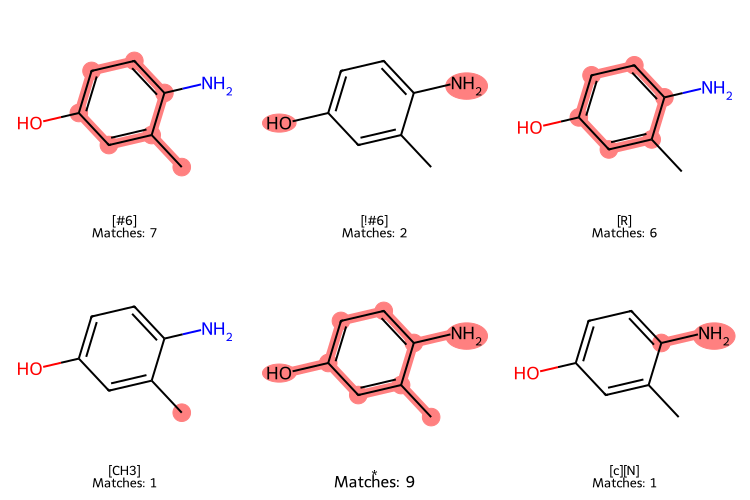

In [8]:
# Ask several chemical questions of the same structure and compare the highlighted answers.
mols_for_grid = []
highlights = []
legends = []

# Start with a simple molecule
smiles = "Cc1cc(O)ccc1N"
mol = Chem.MolFromSmiles(smiles)

# The patterns range from a broad any-atom query to specific features.
patterns = [
    "[#6]",      # Carbon atoms
    "[!#6]",     # Non-carbon atoms
    "[R]",       # Ring atoms
    "[CH3]",     # Methyl group
    "*",         # Any atom
    "[c][N]",    # Aromatic carbon bonded to nitrogen   
]

# Repeat the same search and drawing workflow for each pattern.
for smarts in patterns:
    
    pattern = Chem.MolFromSmarts(smarts)
    
    matches = mol.GetSubstructMatches(pattern)
    
    highlight_atoms = []
    
    for match in matches:
        for atom_idx in match:
            
            if atom_idx not in highlight_atoms:
                highlight_atoms.append(atom_idx)
    
    mols_for_grid.append(mol)
    
    highlights.append(highlight_atoms)
    
    legends.append(f"{smarts}\nMatches: {len(matches)}")

# Put the queries side by side so an unexpected match is visible.
img = Draw.MolsToGridImage(
    mols_for_grid,
    molsPerRow=3,
    subImgSize=(250, 250),
    legends=legends,
    highlightAtomLists=highlights
)

display(img)

### 2.4. Try the idea yourself

You have seen how to turn a chemical feature into a pattern and how to inspect the result. Now try two small questions without looking at the solutions first.

**Exercise A.** The molecule CCN(CC)CC contains nitrogen, but does it contain oxygen? Predict the answer from the structure, then write a SMARTS query that returns a Boolean value.


In [9]:
# Turn the question about oxygen into a SMARTS query before checking the molecule.

molecule = "CCN(CC)CC"

# Your code here


**Exercise B.** The file oxygenated_compounds.csv contains different kinds of oxygen-containing molecules. Find the carboxylic acids and display them. An oxygen-only query would also keep alcohols or esters, so think about what makes an acid different before writing the pattern.


In [10]:
# Choose a pattern that distinguishes a carboxylic acid from other oxygen-containing groups.

csv_file = 'data/oxygenated_compounds.csv'

# Your code here


## 3. Digital reactions

<div style="border-left: 6px solid #ab6747; background: #f5f8fa; border-radius: 0 14px 14px 0; padding: 15px 20px; margin: 12px 0 22px 0;">
  <div style="font: 700 11px/1.4 Arial, sans-serif; letter-spacing: 0.16em; color: #ab6747;">FROM MATCHING TO TRANSFORMING</div>
  <div style="font: 16px/1.55 Arial, sans-serif; color: #29485c; margin-top: 5px;">Encode a reaction once, test it on known substrates, then apply it to a collection of molecules.</div>
</div>


### 3.1. What a reaction template represents

So far, SMARTS has helped us recognize structures. In a synthetic question, recognition is only the beginning: we may also want to draw the product implied by a transformation. Reaction SMARTS places reactant patterns to the left of >> and product templates to the right. Atom-map numbers connect the atoms that remain the same across that change.

A reaction template is a rule for constructing structures, not a prediction of yield, selectivity, or even experimental feasibility. We therefore start with reactants whose expected product we already know and inspect what the rule draws.

### 3.2. From one reaction rule to a product

Acetic acid and methanol give us a familiar esterification example. The first cell defines a generic template and displays it. Follow the mapped atoms across the arrow, especially the oxygen contributed by the alcohol; the following cells will apply that rule to the actual molecules.


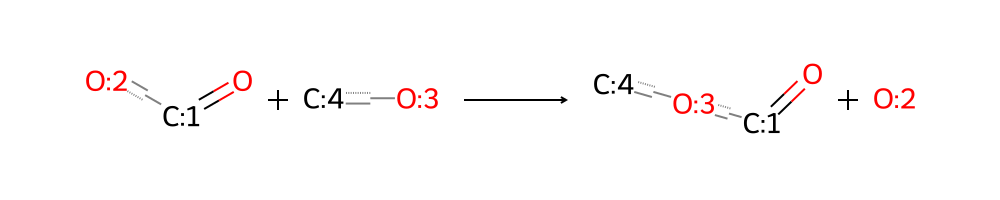

In [11]:
# This template describes a formal esterification, ready to test on familiar reactants.

from rdkit import Chem
from rdkit.Chem import rdChemReactions
from rdkit.Chem import Draw

# Atom-map numbers connect atoms retained across the reaction arrow.
rxn_smarts = "[C:1](=O)[O:2].[O:3][C:4]>>[C:1](=O)[O:3][C:4].[O:2]"
rxn = rdChemReactions.ReactionFromSmarts(rxn_smarts)

# Start with a familiar pair so the proposed ester is easy to judge.
acid = Chem.MolFromSmiles("CC(=O)O")   # acetic acid
alcohol = Chem.MolFromSmiles("CO")     # methanol

display(Draw.ReactionToImage(rxn))

The template is now visible, but it has not yet been applied to acetic acid and methanol. We will give RDKit those two molecules and inspect the product set it returns. Comparing this concrete result with the generic drawing is the first test of whether our rule captures the transformation we intended.


Number of product sets generated: 1
Type of 'products': <class 'tuple'>
Products: ((<rdkit.Chem.rdchem.Mol object at 0x000001CA81E9EC70>, <rdkit.Chem.rdchem.Mol object at 0x000001CA81E9ECE0>),)


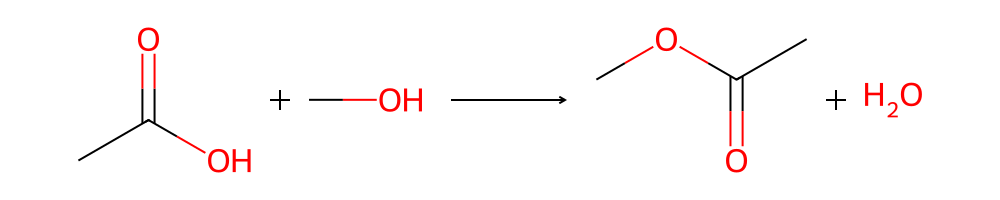

In [12]:
# Use the known acid and alcohol to see what the reaction template actually produces.

products = rxn.RunReactants((acid, alcohol))

print("Number of product sets generated:", len(products))
print("Type of 'products':", type(products))
print("Products:", products)

# One match can return several products in the same outcome.
product_set = products[0]

# Rebuild the image with these specific reactants and products.
reaction_instance = rdChemReactions.ChemicalReaction()
reaction_instance.AddReactantTemplate(acid)
reaction_instance.AddReactantTemplate(alcohol)

for product in product_set:
    reaction_instance.AddProductTemplate(product)

display(Draw.ReactionToImage(reaction_instance))

The result may look unusual at first because RunReactants returns possible outcomes as a collection of product sets. Here, products[0] is the first outcome and products[0][0] is its first product, the ester. A more complicated starting molecule could give several outcomes if the pattern matches at several sites.

To make the transformation easier to read, we will now highlight the atoms selected in each reactant and place them beside the product. This lets us trace the origin of the atoms rather than trusting the product drawing alone.


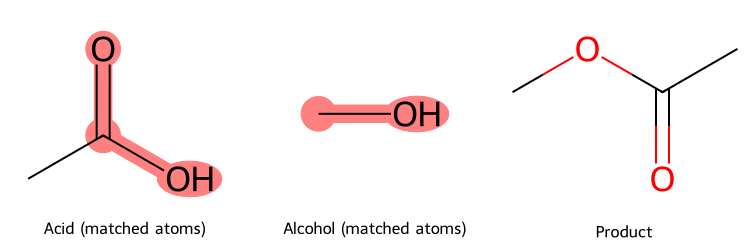

In [13]:
# Highlight the matched atoms to trace their contribution to the ester.

rxn_smarts = "[C:1](=O)[O:2].[O:3][C:4]>>[C:1](=O)[O:3][C:4].[O:2]"
rxn = rdChemReactions.ReactionFromSmarts(rxn_smarts)

acid = Chem.MolFromSmiles("CC(=O)O")
alcohol = Chem.MolFromSmiles("CO")

acid_pattern = Chem.MolFromSmarts("[C:1](=O)[O:2]")
alcohol_pattern = Chem.MolFromSmarts("[O:3][C:4]")

# Find the atoms selected by each reactant-side pattern.
acid_matches = acid.GetSubstructMatches(acid_pattern)
alcohol_matches = alcohol.GetSubstructMatches(alcohol_pattern)

# Drawing these indices lets us compare input atoms with the product.
acid_highlight = [idx for match in acid_matches for idx in match]
alcohol_highlight = [idx for match in alcohol_matches for idx in match]

products = rxn.RunReactants((acid, alcohol))
product = products[0][0]

display(Draw.MolsToGridImage(
    [acid, alcohol, product],
    highlightAtomLists=[acid_highlight, alcohol_highlight, []],
    legends=["Acid (matched atoms)", "Alcohol (matched atoms)", "Product"],
    subImgSize=(250, 250)
))

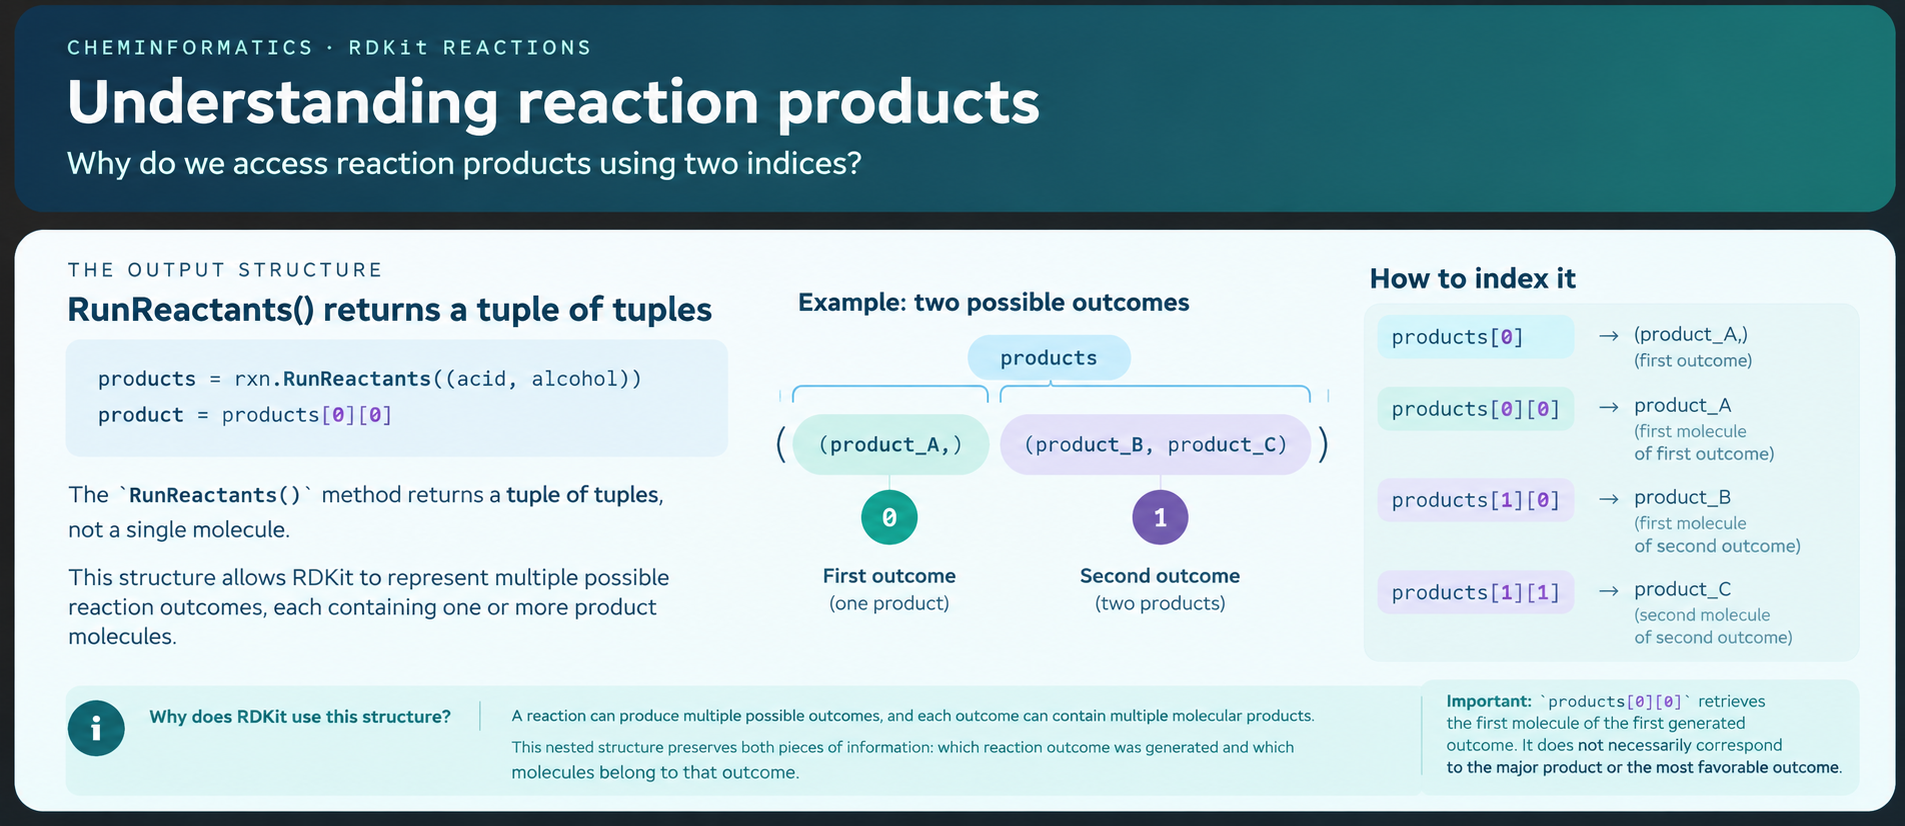

### 3.3. Apply a rule to a collection

A single successful example is encouraging, but the advantage of a digital rule is that it can be reused. We will read a small CSV collection, look at its starting molecules, and then apply a ketone-to-enol template wherever it matches. The drawings are proposed structures; they do not tell us which tautomer would dominate under experimental conditions.


Total molecules: 25


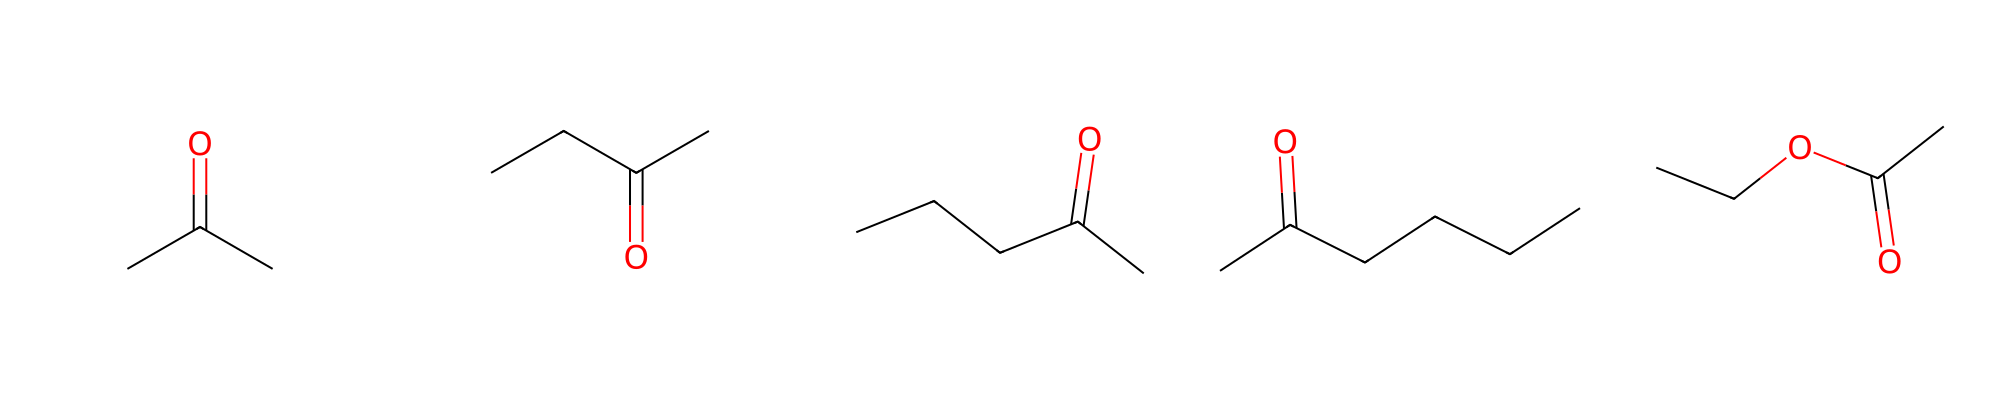

In [14]:
# Inspect the input collection before proposing any products.

df = pd.read_csv("data/oxygenated_compounds.csv")
df["mol_object"] = df["SMILES"].apply(Chem.MolFromSmiles)
print(f"Total molecules: {len(df)}")

# Display the first five valid molecules.
Draw.MolsToGridImage(
    df["mol_object"].dropna().head(5).tolist(),
    molsPerRow=5,
    subImgSize=(400, 400)
)


Now that we have seen the inputs, we can apply the ketone-to-enol rule. The code keeps only molecules for which RDKit finds a match and displays each starting structure beside the first product it generates. Look for the bond and hydrogen changes, and remember that taking the first product is a convenient demonstration rather than a full analysis of every possible site.


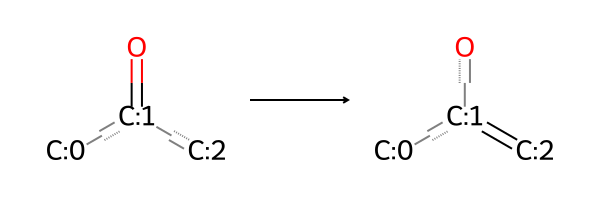

Number of successful reactions: 5


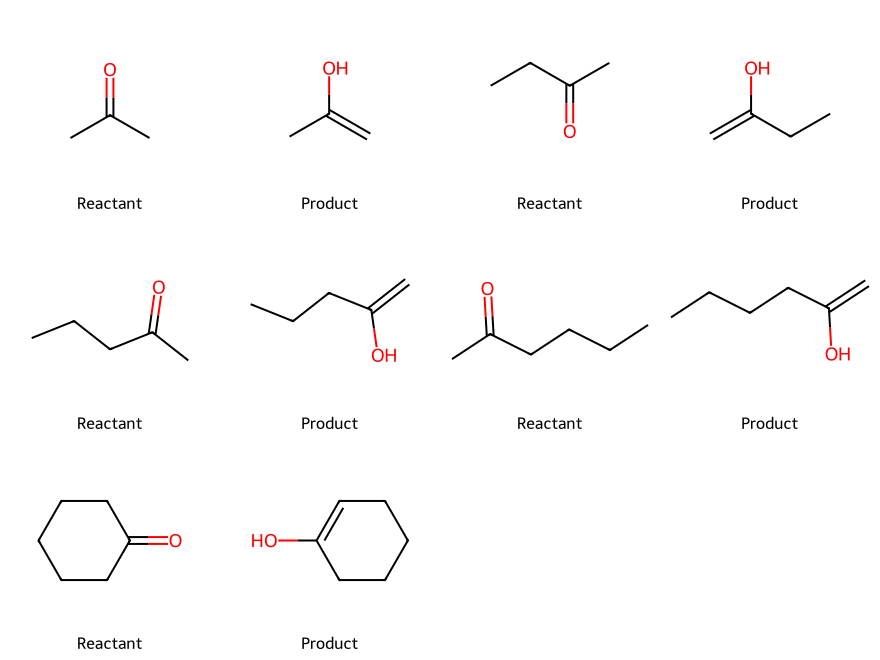

In [15]:
# Apply the same ketone-to-enol rule to every molecule that matches.

valid_mols = [mol for mol in df["mol_object"] if mol is not None]

rxn = rdChemReactions.ReactionFromSmarts(
    "[C:0][C:1](=O)[C:2]>>[C:0][C:1](O)(=[C:2])"
)

reactants = []
products = []

# Molecules without the required ketone motif do not generate a product.
for mol in valid_mols:
    ps = rxn.RunReactants((mol,))
    if ps:
        reactants.append(mol)
        products.append(ps[0][0])  # first product of first match


# Prepare the reactants and products for a side-by-side review of the reaction outcomes
combined = []
legends = []

for r, p in zip(reactants, products):
    combined.extend([r, p])
    legends.extend(["Reactant", "Product"])

display(Draw.ReactionToImage(rxn))

print("Number of successful reactions:", len(products))
# Pair each proposal with its starting structure for review.
display(Draw.MolsToGridImage(
    combined,
    molsPerRow=4,
    legends=legends,
    subImgSize=(220, 220)
))

The paired drawings show the proposed transformations, but a picture is difficult to reuse in another analysis. We will write the reactant and product SMILES into a new CSV in the outputs folder. Keeping both columns makes it possible to trace each proposal back to its starting molecule.


In [16]:
# Save the reactant and product together so the transformation remains traceable.

reactant_smiles = [Chem.MolToSmiles(r) for r in reactants]
product_smiles = [Chem.MolToSmiles(p) for p in products]

reaction_df = pd.DataFrame({
    "reactant_smiles": reactant_smiles,
    "product_smiles": product_smiles
})

# Keep generated results separate from the supplied input files.
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)
reaction_df.to_csv(output_dir / "digital_keto_enol_products.csv", index=False)
reaction_df


,reactant_smiles,product_smiles
0,CC(C)=O,C=C(C)O
1,CCC(C)=O,C=C(O)CC
2,CCCC(C)=O,C=C(O)CCC
3,CCCCC(C)=O,C=C(O)CCCC
4,O=C1CCCCC1,OC1=CCCCC1


## 4. A real Mn complex library

<div style="border-left: 6px solid #7968a5; background: #f5f8fa; border-radius: 0 14px 14px 0; padding: 15px 20px; margin: 12px 0 22px 0;">
  <div style="font: 700 11px/1.4 Arial, sans-serif; letter-spacing: 0.16em; color: #7968a5;">RESEARCH EXAMPLE</div>
  <div style="font: 16px/1.55 Arial, sans-serif; color: #29485c; margin-top: 5px;">Follow the same workflow from a metal core and acid building blocks to candidate complexes.</div>
</div>


This final worked example is closer to an experimental research problem. We have several manganese cores and several carboxylic acids, and we want to explore the structures that result from combining them. The chemistry is more specialized than the esterification above, but the workflow is familiar: inspect the building blocks, encode the structural change, and review the candidate products.

The images provide the chemical context and the coordination motif we will represent. Before applying any rule, we will load the two input lists and draw them.
<figure style="margin: 18px 0 24px 0;">
  <img src="data/images/mn_catalysis.png" alt="Catalytic context for the Mn complexes" style="width: 100%; max-width: 720px; border-radius: 10px;"/>
  <figcaption style="font: 13px/1.5 Arial, sans-serif; color: #647988; margin-top: 5px;">Catalytic context</figcaption>
</figure>

<figure style="margin: 18px 0 24px 0;">
  <img src="data/images/mn_coordination.jpg" alt="Mn coordination reaction scheme" style="width: 100%; max-width: 720px; border-radius: 10px;"/>
  <figcaption style="font: 13px/1.5 Arial, sans-serif; color: #647988; margin-top: 5px;">The coordination step we will represent digitally</figcaption>
</figure>

The structures generated below are candidates for chemical review, not predictions of catalytic performance or experimental success.


Number of acids: 5
Number of metal cores: 5

Carboxylic acids:


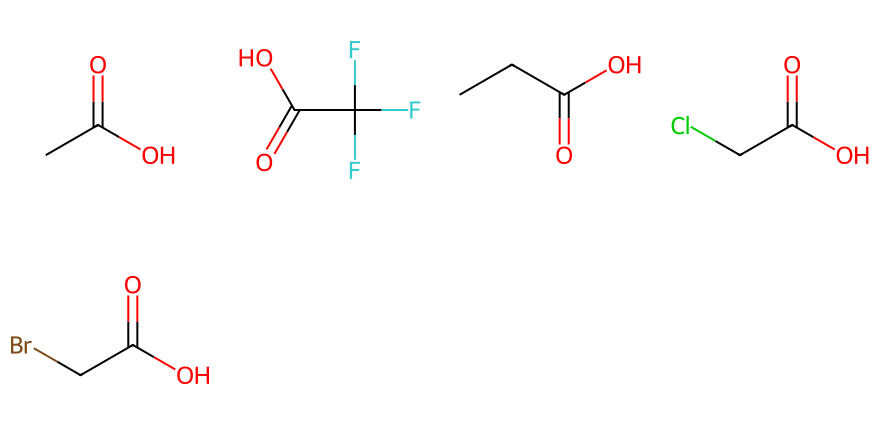


Metal cores:


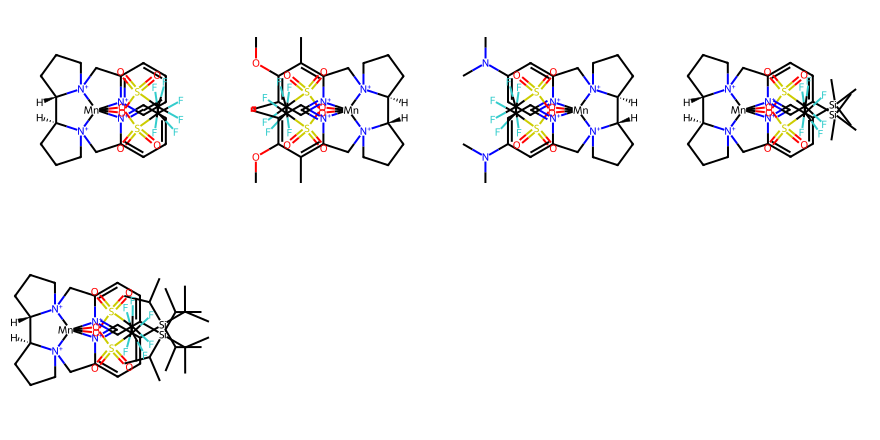

In [17]:
# The Mn workflow begins with two sets of building blocks: cores and acids.

df_acids = pd.read_csv("data/acids.csv")
df_cores = pd.read_csv("data/cores.csv")

print("Number of acids:", len(df_acids))
print("Number of metal cores:", len(df_cores))

acids = []
cores = []

# Skip entries that RDKit cannot parse before combining building blocks.
for smi in df_acids["smiles"]:
    mol = Chem.MolFromSmiles(smi)
    if mol is not None:
        acids.append(mol)

for smi in df_cores["smiles"]:
    mol = Chem.MolFromSmiles(smi)
    if mol is not None:
        cores.append(mol)

# Review both input sets before interpreting the generated library.
print("\nCarboxylic acids:")
display(Draw.MolsToGridImage(
    acids,
    molsPerRow=4,
    subImgSize=(220, 220)
))

print("\nMetal cores:")
display(Draw.MolsToGridImage(
    cores,
    molsPerRow=4,
    subImgSize=(220, 220)
))


The cores and acids are now visible, so we can describe the two changes in the notebook. The first reaction prepares the acid using a temporary Tc marker inside the digital representation; it is a bookkeeping device in the template, not a reagent to add in the lab. The second reaction uses that intermediate to build a Mn-carboxylate structure. We will display both templates before generating a library so the transformation is easier to follow.


Step 1 — Acid activation


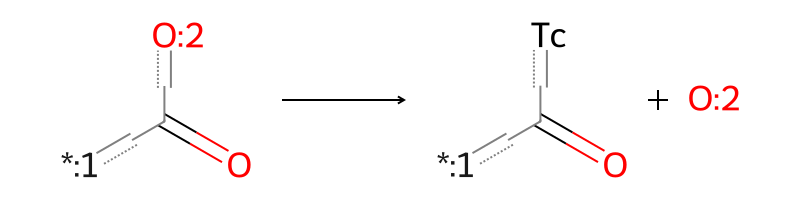

Step 2 — Mn coordination


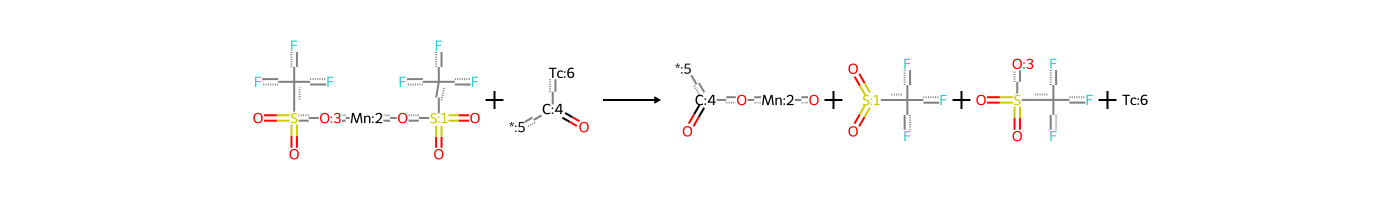

In [18]:
# This function encodes the two formal steps used to build a candidate Mn complex.

def reaction(core, acid):
    """Return a candidate Mn-carboxylate SMILES, or None if no rule matches."""

    # Tc is a temporary structural marker in this digital rule, not a reagent.
    rxn1 = rdChemReactions.ReactionFromSmarts(
        'O=C([OH:2])[*:1]>>O=C([*:1])[Tc].[OH:2]'
    )

    reacts1 = (Chem.MolFromSmiles(acid),)
    products_1 = rxn1.RunReactants(reacts1)

    if not products_1:
        return None

    # The second template replaces that marker while forming the Mn-carboxylate motif.
    rxn2 = rdChemReactions.ReactionFromSmarts(
        'O=[S:1](O[Mn:2][O:3]S(=O)(C(F)(F)F)=O)(C(F)(F)F)=O.'
        'O=[C:4]([Tc:6])[*:5]>>'
        '[*:5][C:4](O[Mn:2]O)=O.'
        'O=[S:1](C(F)(F)F)=O.'
        'O=S([O:3])(C(F)(F)F)=O.'
        '[Tc:6]'
    )

    reacts2 = (
        Chem.MolFromSmiles(core),
        products_1[0][0]
    )

    products_2 = rxn2.RunReactants(reacts2)

    # A missing match means this pair cannot be built with this template.
    if not products_2:
        return None

    product = products_2[0][0]
    Chem.SanitizeMol(product)

    return Chem.MolToSmiles(product, canonical=True)

rxn1 = rdChemReactions.ReactionFromSmarts(
    'O=C([OH:2])[*:1]>>O=C([*:1])[Tc].[OH:2]'
)

rxn2 = rdChemReactions.ReactionFromSmarts(
    'O=[S:1](O[Mn:2][O:3]S(=O)(C(F)(F)F)=O)(C(F)(F)F)=O.'
    'O=[C:4]([Tc:6])[*:5]>>'
    '[*:5][C:4](O[Mn:2]O)=O.'
    'O=[S:1](C(F)(F)F)=O.'
    'O=S([O:3])(C(F)(F)F)=O.'
    '[Tc:6]'
)

print("Step 1 — Acid activation")
display(Draw.ReactionToImage(rxn1))

print("Step 2 — Mn coordination")
display(Draw.ReactionToImage(rxn2))


With both transformations defined, we can try each acid with each Mn core. The resulting table keeps the product together with the two inputs that produced it. That provenance is important: if a structure looks surprising, we can return to the exact core and acid pair and inspect the rule again.


In [19]:
# Enumerate the core-acid pairs only after checking the rule on the structures above.

product_data = []
counter = 1

# Every core is paired with every acid to explore the candidate space.
for core in df_cores["smiles"]:
    for acid in df_acids["smiles"]:

        result = reaction(core, acid)

        if result is not None:
            product_data.append({
                "product_name": f"Mn_complex_{counter}",
                "product_smiles": result,
                "core": core,
                "acid": acid
            })
            counter += 1

# Keep the source core and acid beside each proposed product.
df_complexes = pd.DataFrame(product_data)
print("Total complexes generated:", len(df_complexes))
df_complexes


Total complexes generated: 25


,product_name,product_smiles,core,acid
0,Mn_complex_1,CC(=O)[O][Mn]123([OH])[n+]4ccccc4C[N+]14CCC[C@...,O=S(O[Mn]123([N+]4=C(C=CC=C4)C[N+]15CCC[C@H]5[...,CC(O)=O
1,Mn_complex_2,O=C([O][Mn]123([OH])[n+]4ccccc4C[N+]14CCC[C@H]...,O=S(O[Mn]123([N+]4=C(C=CC=C4)C[N+]15CCC[C@H]5[...,OC(C(F)(F)F)=O
2,Mn_complex_3,CCC(=O)[O][Mn]123([OH])[n+]4ccccc4C[N+]14CCC[C...,O=S(O[Mn]123([N+]4=C(C=CC=C4)C[N+]15CCC[C@H]5[...,OC(CC)=O
3,Mn_complex_4,O=C(CCl)[O][Mn]123([OH])[n+]4ccccc4C[N+]14CCC[...,O=S(O[Mn]123([N+]4=C(C=CC=C4)C[N+]15CCC[C@H]5[...,OC(CCl)=O
4,Mn_complex_5,O=C(CBr)[O][Mn]123([OH])[n+]4ccccc4C[N+]14CCC[...,O=S(O[Mn]123([N+]4=C(C=CC=C4)C[N+]15CCC[C@H]5[...,OC(CBr)=O
5,Mn_complex_6,COc1c(C)c[n+]2c(c1C)C[N+]13CCC[C@H]1[C@@H]1CCC...,CC1=C(C(C)=C2[N+]([Mn]34(OS(=O)(C(F)(F)F)=O)(O...,CC(O)=O
6,Mn_complex_7,COc1c(C)c[n+]2c(c1C)C[N+]13CCC[C@H]1[C@@H]1CCC...,CC1=C(C(C)=C2[N+]([Mn]34(OS(=O)(C(F)(F)F)=O)(O...,OC(C(F)(F)F)=O
7,Mn_complex_8,CCC(=O)[O][Mn]123([OH])[n+]4cc(C)c(OC)c(C)c4C[...,CC1=C(C(C)=C2[N+]([Mn]34(OS(=O)(C(F)(F)F)=O)(O...,OC(CC)=O
8,Mn_complex_9,COc1c(C)c[n+]2c(c1C)C[N+]13CCC[C@H]1[C@@H]1CCC...,CC1=C(C(C)=C2[N+]([Mn]34(OS(=O)(C(F)(F)F)=O)(O...,OC(CCl)=O
9,Mn_complex_10,COc1c(C)c[n+]2c(c1C)C[N+]13CCC[C@H]1[C@@H]1CCC...,CC1=C(C(C)=C2[N+]([Mn]34(OS(=O)(C(F)(F)F)=O)(O...,OC(CBr)=O


## What to take away

We began with a practical problem: how do we get reliable molecular structures into a notebook? Once the drawings agreed with the inputs, SMARTS let us ask which molecules contain a feature and where that feature sits. Reaction SMARTS then turned a checked structural rule into candidate products, first for one familiar pair, then for a collection, and finally for the Mn example.

The habit that links every section is to inspect the chemistry at each step. A successful match means the computer followed the rule we gave it; it does not prove that the proposed reaction will work in the lab. Think of a repeated structure-drawing or substrate-selection task in your own research that could benefit from a carefully tested rule.

## Practice and solutions

### Build an amide library

The longer exercise brings the ideas together. The list below mixes carboxylic acids, primary amines, and an alcohol. First identify the reagents that belong to the amide reaction, then generate and inspect the products from the valid pairs. The alcohol is there to test whether your selection is chemically specific.


In [20]:
# The alcohol is a deliberate negative example in this mixed reagent list.

smiles_list = [
    "CC(=O)O",      # acetic acid
    "CCC(=O)O",     # propionic acid
    "CN",           # methylamine
    "CCN",          # ethylamine
    "CCO"           # alcohol (should not react)
]

# Your code here


### Suggested solutions

Use the solutions to check your reasoning as well as your output. The first question needs only a yes-or-no oxygen match. The second needs a more selective acid pattern. The final solution combines that selection step with a reaction template to build the amides.


In [21]:
# A single oxygen atom is enough for this yes-or-no query.

mol = Chem.MolFromSmiles("CCN(CC)CC")

oxygen_pattern = Chem.MolFromSmarts("[#8]")

contains_oxygen = mol.HasSubstructMatch(oxygen_pattern)

print("Molecule: CCN(CC)CC")
print("Contains oxygen:", contains_oxygen)


Molecule: CCN(CC)CC
Contains oxygen: False


The oxygen question needed only one atom pattern. Selecting acids from a file is more demanding, because the pattern must capture the O-H group attached to a carbonyl rather than oxygen anywhere in the molecule.


Total molecules: 25
Molecules containing carboxylic acid group: 6


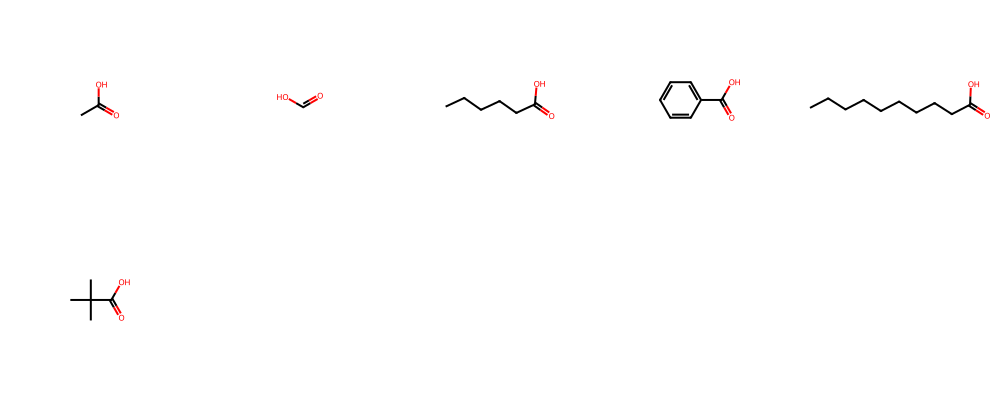

In [22]:
# This solution makes the acid O-H bond explicit before searching for it.

df = pd.read_csv("data/oxygenated_compounds.csv")

molecules = []

for smi in df["SMILES"]:
    mol = Chem.MolFromSmiles(smi)
    if mol is not None:
        mol = Chem.AddHs(mol)  # Make O-H hydrogens explicit for the pattern below      
        molecules.append(mol)

print("Total molecules:", len(molecules))

# This O-H query relies on the explicit hydrogens added above.
acid_pattern = Chem.MolFromSmarts("O=CO[H]")

matched = []

for mol in molecules:
    if mol.HasSubstructMatch(acid_pattern):
        mol = Chem.RemoveHs(mol)  # Remove hydrogens for cleaner visualization
        matched.append(mol)

print("Molecules containing carboxylic acid group:", len(matched))

display(Draw.MolsToGridImage(
    matched,
    molsPerRow=5,
    subImgSize=(200, 200)
))


Once the acids have been selected, the final solution adds primary amines and applies an amide reaction rule to each valid pair. The alcohol should disappear during selection, before any products are generated.


Acids found: 2
Primary amines found: 2


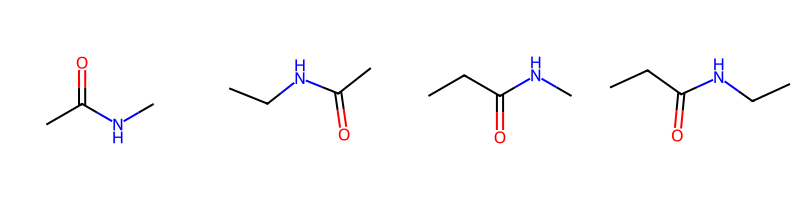

In [23]:
# Select suitable reagents first, then apply the amide rule to their combinations.

smiles_list = [
    "CC(=O)O",      # acetic acid
    "CCC(=O)O",     # propionic acid
    "CN",           # methylamine
    "CCN",          # ethylamine
    "CCO"           # alcohol (should not react)
]

molecules = [Chem.MolFromSmiles(smi) for smi in smiles_list]

# Separate the acid and primary-amine pools before generating products.
acid_pattern = Chem.MolFromSmarts("[CX3](=O)[OH]")
amine_pattern = Chem.MolFromSmarts("[NX3;H2]")

acids = []
amines = []

for mol in molecules:
    if mol.HasSubstructMatch(acid_pattern):
        acids.append(mol)
    if mol.HasSubstructMatch(amine_pattern):
        amines.append(mol)

print("Acids found:", len(acids))
print("Primary amines found:", len(amines))

# The template describes the bond change, not reaction yield.
rxn = rdChemReactions.ReactionFromSmarts(
    "[CX3:1](=O)[OX2H1].[NX3;H2:2]>>[CX3:1](=O)[NX3:2]"
)

products = []

# Combine only the reagents selected by the SMARTS filters.
for acid in acids:
    for amine in amines:
        ps = rxn.RunReactants((acid, amine))
        if ps:
            products.append(ps[0][0])

display(Draw.MolsToGridImage(products, molsPerRow=4))


## Appendix: from ChemDraw to a digital reaction

Many chemists begin with a reaction on a ChemDraw page rather than with a line of SMARTS. The drawing is an excellent chemical starting point, but a computer also needs to know which atoms on the reactant side correspond to atoms on the product side. The reaction basics tutorial explores this idea in MarvinJS; here we follow the same reasoning with a ChemDraw file.

Imagine drawing a carboxylic acid and a primary amine forming an amide. Map the atoms that remain in the amide, and leave the departing acid hydroxyl oxygen without a product map number. It is also worth checking that the drawing describes the acid and the primary amine specifically enough: otherwise a digital rule may accept reactants you did not intend.

Save the complete scheme, including its arrow, as data/amide_from_chemdraw.cdxml. The next cell reads it if the file is present. Without a ChemDraw file, it uses a mapped tutorial example so that you can still see and test the same workflow. The reaction image and validation messages are a first check; the familiar product test that follows is the more useful one.


Using the mapped tutorial example. Add a ChemDraw CDXML file to try your own scheme.
Validation: 0 warning(s), 0 error(s)
Reactant templates: 2


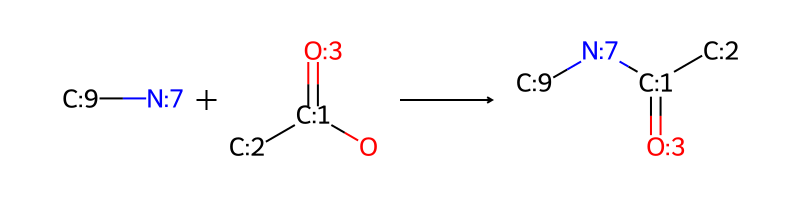

In [24]:
# Use a ChemDraw CDXML reaction when available, otherwise keep the tutorial template as a test case.

amide_smarts = (
    "[#7H2:7]-[#6:9].[#8H]-[#6:1](-[#6:2])=[O:3]"
    ">>[#6:9]-[#7:7]-[#6:1](-[#6:2])=[O:3]"
)
chemdraw_file = Path("data/amide_from_chemdraw.cdxml")

# A drawing must contain one complete reaction scheme to be imported.
if chemdraw_file.exists():
    imported_reactions = rdChemReactions.ReactionsFromCDXMLFile(str(chemdraw_file))
    if len(imported_reactions) != 1:
        raise ValueError("The CDXML file must contain exactly one reaction scheme.")
    amide_reaction = imported_reactions[0]
    print("Loaded reaction from ChemDraw CDXML.")
else:
    amide_reaction = rdChemReactions.ReactionFromSmarts(amide_smarts)
    print("Using the mapped tutorial example. Add a ChemDraw CDXML file to try your own scheme.")

# Validation is an early check; the product test below is still essential.
warnings, errors = amide_reaction.Validate()
print(f"Validation: {warnings} warning(s), {errors} error(s)")
print(f"Reactant templates: {amide_reaction.GetNumReactantTemplates()}")
display(Draw.ReactionToImage(amide_reaction))


We now have a reaction object, either from the ChemDraw file or from the example template. To test it, we choose methylamine and acetic acid, whose expected amide is easy to recognize. If RDKit produces no product, the issue may be the reactant order, atom maps, hydrogen requirements, or the way the scheme was saved. If it does produce a product, inspect the drawing and SMILES before trusting the rule with a larger set.


First product: CNC(C)=O


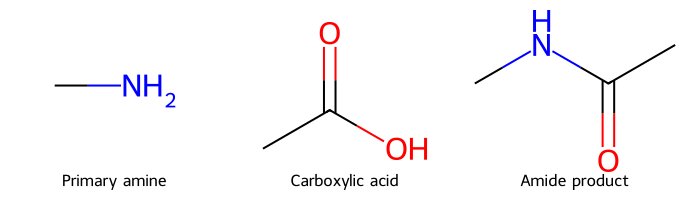

In [25]:
# Test the rule on a familiar acid-amine pair before using it more widely.

amine = Chem.MolFromSmiles("CN")          # Methylamine
carboxylic_acid = Chem.MolFromSmiles("CC(=O)O")  # Acetic acid
# The result depends on the reactant order encoded in the template.
amide_products = amide_reaction.RunReactants((amine, carboxylic_acid))

if not amide_products:
    print("No product matched. Recheck the drawn template and reactant order.")
else:
    amide_product = amide_products[0][0]
    Chem.SanitizeMol(amide_product)
    print("First product:", Chem.MolToSmiles(amide_product))
    display(Draw.MolsToGridImage(
        [amine, carboxylic_acid, amide_product],
        legends=["Primary amine", "Carboxylic acid", "Amide product"],
        subImgSize=(230, 200),
    ))
